# Water Quality Lab: Análisis de indicadores microbiológicos en masas de agua de España

## Análisis exploratorio de datos (EDA)

Este análisis utiliza el conjunto de datos de [Open Water Quality](https://openwaterquality.org/), que contiene registros de mediciones de calidad microbiológica del agua.

Cada fila representa una medición individual de un indicador microbiológico en una ubicación y fecha determinadas. 
Los registros incluyen información sobre el indicador analizado, su valor, la unidad de medida, la localización geográfica y el tipo de masa de agua.

El objetivo es explorar los datos y estudiar cómo se distribuyen los indicadores microbiológicos en España, qué diferencias se observan entre ellos y cómo varían los registros según la ubicación y el tipo de masa de agua. Los resultados servirán como base para desarrollar una aplicación interactiva que permita consultar y visualizar los datos.

## Preguntas de investigación

1. ¿Qué indicadores microbiológicos aparecen con mayor frecuencia?
2. ¿Cómo se distribuyen geográficamente las muestras?
3. ¿Cómo han evolucionado los registros a lo largo del tiempo?
4. ¿Existen diferencias entre los distintos tipos de masas de agua?
5. ¿Qué diferencias existen entre los niveles registrados de E. coli y Enterococci?
6. ¿Qué diferencias se observan entre las regiones de España en los resultados de los análisis microbiológicos?

## Mis datos

- **Fuente:** [Open Water Quality](https://openwaterquality.org/).
- **Ámbito geográfico:** España.
- **Periodo disponible:** febrero de 2013 – julio de 2015.
- **Número de registros:** 100.000.
- **Qué representa cada fila:** una medición individual de un indicador microbiológico.
- **Indicadores analizados:** E. coli y Enterococci.
- **Tipos de masas de agua:** ríos y arroyos, estuarios, lagos y otros.

**Preguntas del análisis interactivo:** ¿Qué resultados encontramos en una zona y tipo de agua determinados?

- **Indicador microbiológico:** podrá seleccionar E. coli o Enterococci.
- **Tipo de masa de agua:** podrá elegir la categoría que quiera explorar.
- **Región geográfica:** podrá consultar los registros de una región de España.

A partir de sus selecciones, la aplicación mostrará el número de muestras, los valores registrados, su evolución temporal y su distribución geográfica.

**Nota:** la descarga está limitada a 100.000 registros, por lo que el conjunto de datos puede no incluir todas las observaciones disponibles en la fuente original.

## 0. Comprobación

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import streamlit as st

print("Microbial Water Monitor: entorno preparado")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Water Quality Lab: entorno preparado
Pandas: 3.1.1
NumPy: 2.5.4


## 1. ¿Qué tengo?

Empieza por ver qué hay en la tabla.

**1.1** Carga tu CSV de la carpeta datos en una tabla con un nombre que diga qué es (como pisos o titanic) y enseña las primeras filas.

In [70]:
# Carga el archivo csv en una tabla de pandas:

aguas = pd.read_csv("datos/datos_originales.csv", comment="#")  # El parámetro comment="#" le indica a Pandas que ignore las líneas que comienzan por #.

aguas.head() # se muestran las cinco primeras filas,.

,date,indicator,value,unit,latitude,longitude,source,region,water_body
0,2013-02-18,E. coli,15.0,CFU/100mL,28.9571,-13.5513,Eionet,Spain,other
1,2013-02-18,E. coli,1.0,CFU/100mL,27.7435,-15.5680,Eionet,Spain,other
2,2013-02-18,E. coli,1.0,CFU/100mL,27.7360,-15.5917,Eionet,Spain,other
3,2013-02-18,E. coli,1.0,CFU/100mL,27.7448,-15.6126,Eionet,Spain,other
4,2013-02-18,E. coli,1.0,CFU/100mL,27.7630,-15.5592,Eionet,Spain,other


**1.2** ¿Cuántas filas y columnas tiene?

In [71]:
aguas.shape

(100000, 9)

**1.3** Mira el info(). ¿De qué tipo es cada columna? ¿Cuáles tienen huecos?

In [72]:
aguas.info()

# El conjunto de datos original tiene 100.000 registros y 9 columnas.
# No parece haber valores ausentes.


<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   date        100000 non-null  str    
 1   indicator   100000 non-null  str    
 2   value       100000 non-null  float64
 3   unit        100000 non-null  str    
 4   latitude    100000 non-null  float64
 5   longitude   100000 non-null  float64
 6   source      100000 non-null  str    
 7   region      100000 non-null  str    
 8   water_body  100000 non-null  str    
dtypes: float64(3), str(6)
memory usage: 11.1 MB


**1.4** Quédate con las columnas que te sirven para tu pregunta, o quita las que sobran.

In [73]:
aguas = aguas.drop(columns=["source"])

**1.4.b** Transformamos date de texto (str) a formato fecha de Pandas (datetime).

In [74]:
aguas["date"] = pd.to_datetime(aguas["date"])

**1.5** Si los nombres de las columnas están en inglés o son raros, ponles nombres en español.

In [75]:
aguas.columns = ["fecha", "indicador", "valor", "unidad", "latitud", "longitud", "region", "tipo_agua"]

aguas.head()

,fecha,indicador,valor,unidad,latitud,longitud,region,tipo_agua
0,2013-02-18,E. coli,15.0,CFU/100mL,28.9571,-13.5513,Spain,other
1,2013-02-18,E. coli,1.0,CFU/100mL,27.7435,-15.5680,Spain,other
2,2013-02-18,E. coli,1.0,CFU/100mL,27.7360,-15.5917,Spain,other
3,2013-02-18,E. coli,1.0,CFU/100mL,27.7448,-15.6126,Spain,other
4,2013-02-18,E. coli,1.0,CFU/100mL,27.7630,-15.5592,Spain,other


**Lo que he visto y lo que he decidido:**

El archivo original contiene 100.000 registros y 9 columnas, sin valores nulos. Para cargarlo correctamente he utilizado `comment="#"`, ya que el CSV incluye líneas de comentarios antes de los datos.

He observado que los registros contienen dos indicadores microbiológicos, E. coli y Enterococci, junto con información sobre sus mediciones, fechas y ubicación geográfica.

He decidido eliminar la columna `source` del conjunto de trabajo, porque no la necesito para las preguntas que quiero investigar, aunque la conservaré en el archivo original. También he mantenido `value` y `unit`, ya que ambas son necesarias para interpretar los resultados.

Por último, he traducido los nombres de las columnas al español y he convertido `fecha` de texto a formato fecha (`datetime64[us]`). Con estos cambios, tengo un conjunto de 100.000 registros y 8 columnas preparado para continuar con el análisis.

## 2. ¿Qué me falta?

Cuenta lo que falta y decide qué haces con cada columna.

**2.1** Cuenta los huecos de cada columna.

In [76]:
# isna() comprueba qué valores están ausentes.
# sum() cuenta los valores ausentes de cada columna.

aguas.isna().sum()

# No hay valores ausentes

fecha        0
indicador    0
valor        0
unidad       0
latitud      0
longitud     0
region       0
tipo_agua    0
dtype: int64

**2.2** Calcula el porcentaje de huecos de cada columna.

In [77]:
porcentaje = aguas.isna().sum() / len(aguas) * 100
# Se calcula el porcentaje de huecos despecto al total de filas.

porcentaje.round(2)
# se redondea a dos decimales.


# Ya sabemos que no hay, pero hacemos el ejercicio para practicar.

fecha        0.0
indicador    0.0
valor        0.0
unidad       0.0
latitud      0.0
longitud     0.0
region       0.0
tipo_agua    0.0
dtype: float64

**2.3** Decide qué haces con cada columna que tenga huecos: quitar la columna, quitar esas filas o rellenarlos. Hazlo.

In [78]:
# Como no hay huecos, no eliminamos nada.

**2.4** Comprueba que ya no quedan huecos, o que los que quedan los dejas a propósito.

In [79]:
# -

**2.5** Mira con value_counts las columnas de texto. ¿Hay algún hueco disfrazado, como "Unknown", "-" o "N/A"?

In [80]:
print(aguas["indicador"].value_counts())
print(aguas["unidad"].value_counts())
print(aguas["region"].value_counts())
print(aguas["tipo_agua"].value_counts())

# No se detectan valores ausentes

indicador
E. coli        50325
Enterococci    49675
Name: count, dtype: int64
unidad
CFU/100mL    100000
Name: count, dtype: int64
region
Spain    100000
Name: count, dtype: int64
tipo_agua
other           87207
river/stream     4785
estuary          4633
lake             3375
Name: count, dtype: int64


**Lo que he visto y lo que he decidido:**

He comprobado si existen valores nulos o datos ausentes ocultos. Primero he utilizado `isnull().sum()` y he observado que ninguna de las ocho columnas contiene valores nulos. 

Después he revisado las categorías de las columnas de texto para detectar posibles etiquetas como «Unknown», «N/A» o guiones que pudieran representar información ausente y no he encontrado ninguna, por lo que he decidido no realizar ninguna sustitución ni eliminación de datos, ya que no es necesario tratar valores ausentes en este conjunto.

## 3. ¿Hay filas repetidas?

Comprueba si hay algo contado dos veces.

**3.1** ¿Cuántas filas repetidas hay?

In [81]:
print("Filas repetidas:", aguas.duplicated().sum())

# Con el resultado podemos afirmar que los 100.000 registros son únicos.

Filas repetidas: 0


**3.2** Si tienes una columna que identifica cada fila (un id, un nombre), ¿hay algún valor repetido?

In [82]:
# No disponemos de un identificador único y no hemos encontrado registros completamente duplicados.

aguas.duplicated().sum()

np.int64(0)

**3.3** Decide si las quitas, y hazlo. Si no son la misma fila, no se quitan.

In [83]:
# No hay que eliminar ningún registro, porque no hemos encontrado filas completamente duplicadas.

aguas = aguas.drop_duplicates()
aguas.shape 

(100000, 8)

**Lo que he visto y lo que he decidido:**

He comprobado que no existe una columna identificadora única para cada registro y también he revisado las filas duplicadas: el resultado ha sido 0. 
Por tanto, he decidido conservar todos los registros, ya que no hay filas completamente repetidas que sea necesario eliminar.

La tabla se queda con los mismos datos: 100.000 registros, 8 columnas.

## 4. ¿Cómo son los números?

Mira los números con el describe, la media, la mediana y un histograma.

**4.1** Haz el describe. ¿Qué te llama la atención?

In [84]:
aguas.describe()

# Media: 30,45, mientras que la mediana es 6. Esto indica que algunos valores elevados están haciendo subir la media.
# Percentiles: el 50 % de las mediciones tiene un valor igual o inferior a 6, y el 75 % no supera 14.
# Máximo: aparece un valor de 100.000, muy alejado del resto de los datos. Conviene investigarlo porque podría ser un valor extremo.
# Desviación estándar: 524,46, bastante elevada en comparación con la media.
# Fechas: los registros abarcan desde febrero de 2013 hasta julio de 2015.

,fecha,valor,latitud,longitud
count,100000,100000.000000,100000.000000,100000.000000
mean,2014-04-28 18:08:02.112000,30.449814,38.965094,-4.399808
min,2013-02-18 00:00:00,1.000000,27.735200,-17.947200
25%,2013-08-05 00:00:00,2.000000,37.115500,-8.488200
50%,2014-06-16 00:00:00,6.000000,39.703300,-3.669900
75%,2014-09-08 00:00:00,14.000000,42.426900,-0.113800
max,2015-07-20 00:00:00,100000.000000,43.769800,4.301700
std,NaN,524.462449,4.424985,5.494195


**4.2** Saca la media y la mediana de la columna de números más importante para tu pregunta. ¿Se parecen?

In [85]:
# La columna más importante para nuestro análisis es valor, porque contiene los resultados de las mediciones microbiológicas.

print("Valoración media:", round(aguas["valor"].mean(), 2))
print("Valoración mediana:", round(aguas["valor"].median(), 2))

Valoración media: 30.45
Valoración mediana: 6.0


**4.3** Dibuja su histograma.

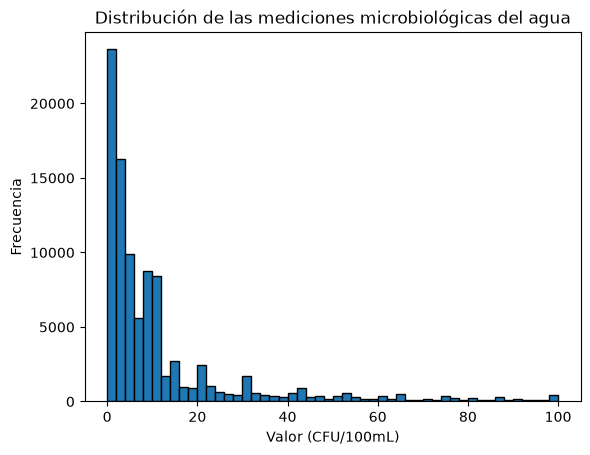

In [86]:
aguas["valor"].plot(
    kind="hist",
    bins=50,
    edgecolor="black",
    range=(0, 100),
    title="Distribución de las mediciones microbiológicas del agua"
)

plt.xlabel("Valor (CFU/100mL)")
plt.ylabel("Frecuencia")
plt.show()

**4.4** Haz lo mismo con otra columna de números.

In [87]:
aguas["fecha"].dt.year.value_counts().sort_index()

fecha
2013    39746
2014    40464
2015    19790
Name: count, dtype: int64

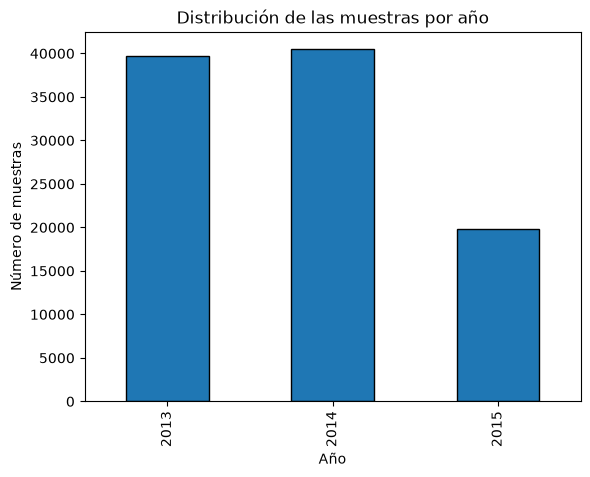

In [88]:
aguas["fecha"].dt.year.value_counts().sort_index().plot(
    kind="bar",
    title="Distribución de las muestras por año",
    edgecolor="black"
)

plt.xlabel("Año")
plt.ylabel("Número de muestras")
plt.show()

**Lo que he visto y lo que he decidido:**

Al utilizar `describe()` he obtenido un resumen estadístico de las columnas numéricas y de la fecha. 
Lo que más me ha llamado la atención es la diferencia entre la media (30,45) y la mediana (6) de la columna valor. 
Además, el 75 % de las mediciones no supera 14, pero encontramos un máximo de 100.000. Esto provoca una desviación estándar muy elevada y podría indicar la presencia de valores extremos. 

He calculado la media y la mediana de la columna valor. La media es 30,45 y la mediana es 6, por lo que existe una diferencia considerable entre ambas, lo sugiere que hay valores muy elevados que influyen en la media y que la distribución está sesgada hacia la derecha. 
Por ello, la mediana puede representar mejor el valor central de las mediciones.

Al representar la distribución de los valores mediante un histograma, he observado que la mayoría de las mediciones se concentran en valores bajos y que existe una cola hacia la derecha debido a algunos valores elevados. Esto confirma la diferencia entre la media y la mediana y la posible presencia de valores extremos. 
He decidido conservarlos por ahora y estudiarlos con más detalle antes de considerar si alguno debe eliminarse.

También he analizado la distribución de las muestras por año. En 2013 se registraron 39.746 muestras y en 2014, 40.464, por lo que ambos años presentan cifras muy similares. En 2015 el número desciende a 19.790. Esto puede explicarse porque los datos de ese año solo llegan hasta julio (por lo que 2015 no es un año completo).

## 5. ¿Hay algo raro?

Busca los valores extremos y decide si son errores o casos reales.

**5.1** Enseña las 5 filas con el valor más alto de tu columna principal.

In [89]:
# sort_values: ordena las reseñas según la valoración.
# ascending=False: ordena de mayor a menor.

aguas.sort_values("valor", ascending=False).head()

# Qué llama la atención:
    # Los cinco valores son muy superiores a la mediana (6).
    # Aparecen los dos indicadores microbiológicos.
    # Todas las muestras pertenecen a la categoría other.
    # Las coordenadas de las muestras están bastante próximas entre sí, en torno a 39° de latitud y 3° de longitud.
# Todavía no podemos afirmar que sean errores.

,fecha,indicador,valor,unidad,latitud,longitud,region,tipo_agua
57342,2014-07-14,E. coli,100000.0,CFU/100mL,39.3608,3.2244,Spain,other
16962,2013-07-08,E. coli,86000.0,CFU/100mL,39.9102,3.0871,Spain,other
58437,2014-07-14,Enterococci,69000.0,CFU/100mL,39.3608,3.2244,Spain,other
98478,2015-07-13,Enterococci,40500.0,CFU/100mL,39.5375,2.4222,Spain,other
33009,2013-09-02,E. coli,31000.0,CFU/100mL,39.9081,3.0846,Spain,other


**5.2** Y las 5 con el más bajo. ¿Hay ceros o valores imposibles?

In [90]:
aguas.sort_values("valor", ascending=True).head()

# Hay varios aspectos interesantes:
    # Los cinco valores más bajos son 1 CFU/100mL. 
    # No aparecen ceros entre las cinco mediciones más bajas.
    # Tampoco aparecen valores negativos.
    # Todas las muestras corresponden a E. coli.
    # Todas pertenecen a la categoría other.
    # Las mediciones están registradas entre febrero de 2013 y julio de 2014.

,fecha,indicador,valor,unidad,latitud,longitud,region,tipo_agua
38,2013-02-18,E. coli,1.0,CFU/100mL,28.3780,-16.7239,Spain,other
56536,2014-07-08,E. coli,1.0,CFU/100mL,43.4655,-3.4663,Spain,other
56535,2014-07-08,E. coli,1.0,CFU/100mL,43.3863,-3.2253,Spain,other
15,2013-02-18,E. coli,1.0,CFU/100mL,27.7981,-15.7311,Spain,other
14,2013-02-18,E. coli,1.0,CFU/100mL,27.8243,-17.8952,Spain,other


**5.3** Haz el diagrama de caja de esa columna.

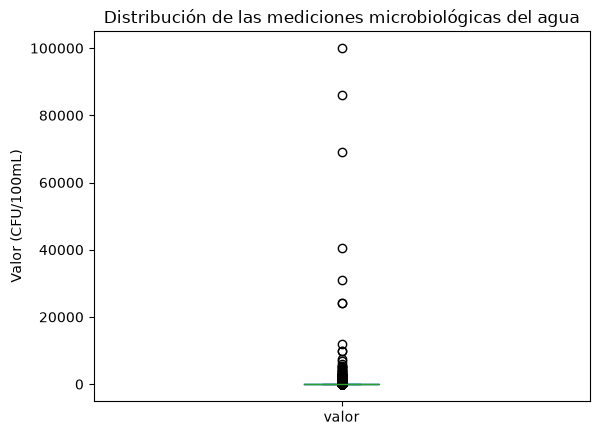

In [91]:
# Qué representa el diagrama:
    # La línea dentro de la caja: mediana.
    # La caja: intervalo entre el primer y el tercer cuartil.
    # Los bigotes: extensión de los valores que no se consideran atípicos según el criterio # Los puntos fuera de los bigotes: posibles valores atípicos.

aguas["valor"].plot(
    kind="box",
    title="Distribución de las mediciones microbiológicas del agua"
)

plt.ylabel("Valor (CFU/100mL)")
plt.show()

# Tres aspectos que destacan:
    # La caja está muy comprimida: la mayoría de las mediciones se concentran en valores bajos.
    # Hay muchos puntos fuera de los bigotes: son valores que el criterio del diagrama identifica como atípicos.
    # Existen valores extremos muy elevados: destacan especialmente los de 40.500, 69.000, 86.000 y 100.000.

**5.4** Decide qué haces con cada valor raro: si es un error, corrígelo o quítalo; si es real, se queda.

In [92]:
# Conservamos los valores extremos porque:
    # Todos tienen una unidad válida: CFU/100mL.
    # No son valores negativos ni ceros.
    # Pertenecen a registros con fecha, indicador y coordenadas.
    # No tenemos pruebas de que sean errores de medición.

**Lo que he visto y lo que he decidido:**

## Lo que he observado y decidido

Al investigar los valores extremos de la columna `valor`, he observado que existen mediciones muy elevadas, que llegan hasta 100.000 CFU/100mL, mientras que los cinco valores más bajos son de 1 CFU/100mL. 
No he encontrado ceros ni valores negativos entre las cinco mediciones más bajas.

El diagrama de caja muestra numerosos valores atípicos y una distribución muy concentrada en los valores pequeños. También he comprobado que los registros con valores más elevados pertenecen a los dos indicadores microbiológicos y están clasificados como `other`.

Un valor atípico no tiene por qué ser un error. Como no tengo pruebas de que estas mediciones sean incorrectas, he decidido conservarlas y no eliminar ningún registro.

## 6. ¿Qué hay más?

Cuántas filas hay de cada tipo.

**6.1** Haz el value_counts de la columna de texto más importante, en número y en porcentaje.

In [ ]:
# Se va a utilizar indicador, porque es la columna de texto más importante comparar E. coli y Enterococci.

# Contamos cuántas muestras hay de cada indicador microbiológico.

aguas["indicador"].value_counts()

indicador
E. coli        50325
Enterococci    49675
Name: count, dtype: int64

In [ ]:
# Calculamos el porcentaje de cada indicador.

aguas["indicador"].value_counts(normalize=True) * 100

indicador
E. coli        50.325
Enterococci    49.675
Name: proportion, dtype: float64

In [ ]:
# Los resultados confirman lo que ya habíamos visto:
    # E. coli: 50.325 muestras (50,325 %).
    # Enterococci: 49.675 muestras (49,675 %).
# La distribución está prácticamente equilibrada, con una diferencia de solo 650 muestras.

**6.2** Dibújalo en barras.

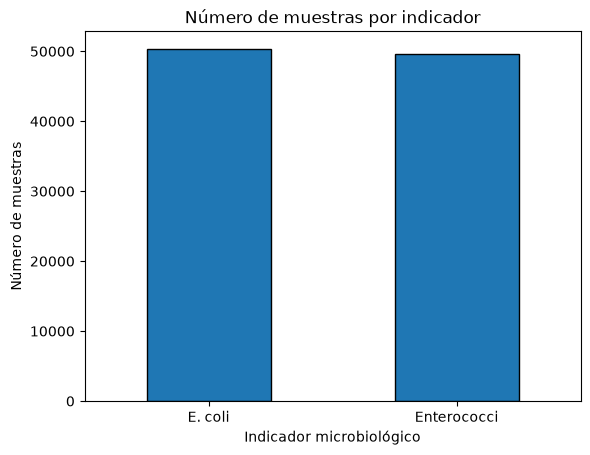

In [97]:
# Representamos el número de muestras de cada indicador.

aguas["indicador"].value_counts().plot(
    kind="bar",
    edgecolor="black",
    title="Número de muestras por indicador"
)

plt.xlabel("Indicador microbiológico")
plt.ylabel("Número de muestras")
plt.xticks(rotation=0)
plt.show()

**Lo que he visto y lo que he decidido:**

En este apartado he analizado la distribución de los dos indicadores microbiológicos mediante frecuencias y porcentajes. 
Se puede observar que E. coli representa 50.325 muestras (50,325 %) y Enterococci 49.675 muestras (49,675 %). 
El gráfico de barras muestra que ambos indicadores tienen una representación prácticamente equilibrada, con una diferencia de solo 650 registros.

He decidido conservar ambos indicadores para los siguientes análisis, ya que tienen una cantidad de muestras muy similar y esto permitirá compararlos sin que exista un desequilibrio importante en el número de observaciones.

## 7. ¿Cambia algo de un grupo a otro?

Aquí es donde suelen salir los hallazgos.

**7.1** Con groupby, calcula la media o la mediana de tu columna principal en cada grupo.

In [ ]:
# Calculamos la mediana de los valores de cada indicador
    # groupby("indicador"): agrupa los registros según el indicador microbiológico.
    # ["valor"]: selecciona la columna que queremos analizar.
    # .median(): calcula la mediana de cada grupo.
    # sort_values(ascending=False): ordena los resultados de mayor a menor.

aguas.groupby("indicador")["valor"].median().sort_values(ascending=False)

indicador
E. coli        6.0
Enterococci    5.0
Name: valor, dtype: float64

**7.2** Haz otra comparación con otra columna de grupos.

In [99]:
# Investigamos qué tipos de masas de agua concentran un mayor número de muestras.

aguas["tipo_agua"].value_counts().head(10)

tipo_agua
other           87207
river/stream     4785
estuary          4633
lake             3375
Name: count, dtype: int64

**7.3** Antes de sacar conclusiones, mira cuántas filas tiene cada grupo. ¿Hay alguno con muy pocas?

In [ ]:
# Comprobamos cuántas muestras tiene cada categoría de las dos comparaciones anteriores.

print("Muestras por indicador:")
print(aguas["indicador"].value_counts())

print("Muestras por tipo de agua:")
print(aguas["tipo_agua"].value_counts())

# Los grupos tienen tamaños muy diferentes según la variable que analicemos:
    # Por indicador: la distribución está equilibrada. E. coli tiene 50.325 muestras y Enterococci, 49.675. La diferencia es pequeña.
    # Por tipo de agua: existe un desequilibrio importante. other reúne 87.207 muestras, mientras que las otras tres categorías tienen entre 3.375 y 4.785.

Muestras por indicador:
indicador
E. coli        50325
Enterococci    49675
Name: count, dtype: int64
Muestras por tipo de agua:
tipo_agua
other           87207
river/stream     4785
estuary          4633
lake             3375
Name: count, dtype: int64


**Lo que he visto y lo que he decidido:**

He agrupado las mediciones por indicador y he calculado la mediana de cada uno. 
E. coli presenta una mediana de 6 CFU/100mL, mientras que Enterococci tiene una mediana de 5 CFU/100mL. Los resultados son bastante similares, aunque E. coli presenta un valor central ligeramente superior. 
He utilizado la mediana porque los datos contienen valores extremos que podrían distorsionar la media.

También he analizado la distribución de las muestras según el tipo de masa de agua. He observado que la categoría `other` concentra 87.207 registros (87,21 % del total), mientras que `river/stream` representa el 4,79 %, `estuary` el 4,63 % y `lake` el 3,38 %. Esto supone un desequilibrio importante entre categorías que tendré que tener en cuenta al comparar los resultados.

Antes de continuar, he comprobado el tamaño de cada grupo. Por indicador, la distribución está prácticamente equilibrada: E. coli cuenta con 50.325 muestras (50,33 %) y Enterococci con 49.675 (49,68 %). 
Por tipo de agua, en cambio, la diferencia es mucho mayor debido al peso de la categoría `other`.

He decidido conservar todos los grupos, ya que forman parte de los datos disponibles y no hay motivos para eliminar ninguna categoría. Sin embargo, tendré en cuenta las diferencias en el número de muestras al interpretar las comparaciones, especialmente las relacionadas con los tipos de masas de agua.

## 8. ¿Van juntas dos columnas?

Comprueba si dos columnas de números tienen relación.

**8.1** Calcula la correlación entre dos columnas de números.

In [ ]:
# Calculamos la correlación entre el valor de las mediciones y las coordenadas geográficas.

correlacion_latitud = aguas["valor"].corr(aguas["latitud"])
correlacion_longitud = aguas["valor"].corr(aguas["longitud"])

print("Correlación con la latitud:", round(correlacion_latitud, 2))
print("Correlación con la longitud:", round(correlacion_longitud, 2))

# no se observa una relación lineal entre el valor de las mediciones y las coordenadas geográficas.

Correlación con la latitud: 0.02
Correlación con la longitud: 0.01


**8.2** Haz el gráfico de puntos de esas dos columnas.

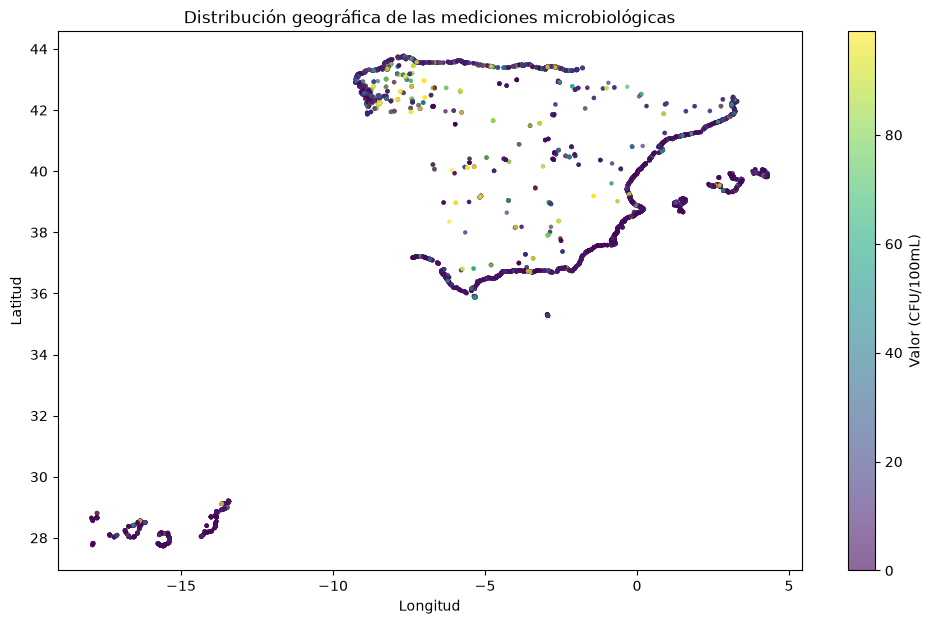

In [ ]:
# Seleccionamos una muestra aleatoria de 10.000 registros.

muestra = aguas.sample(n=10000, random_state=42)

# Calculamos el percentil 95 de los valores.

limite_color = muestra["valor"].quantile(0.95)

# Representamos las muestras según sus coordenadas geográficas.

plt.figure(figsize=(12, 7))

plt.scatter(
    muestra["longitud"],
    muestra["latitud"],
    c=muestra["valor"],
    s=5,
    alpha=0.6,
    cmap="viridis",
    vmin=0,
    vmax=limite_color
)

plt.colorbar(label="Valor (CFU/100mL)")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.title("Distribución geográfica de las mediciones microbiológicas")

plt.show()

**Lo que he visto y lo que he decidido:**

He calculado la correlación entre los valores de las mediciones y las coordenadas geográficas. El resultado ha sido de 0,02 para la latitud y 0,01 para la longitud. Ambos valores están muy próximos a cero, por lo que no he encontrado una relación lineal entre estas variables. 
Esto no descarta que existan diferencias geográficas, sino que indica que no se aprecia una relación lineal general entre la ubicación y los valores registrados.

Después he representado geográficamente una muestra aleatoria de 10.000 registros. Se observa que las mediciones se distribuyen por la península y los archipiélagos, aunque no de manera uniforme: hay zonas con una mayor concentración de puntos y otras con menos registros.

En el primer gráfico he visto que los valores extremos dificultaban distinguir las diferencias entre las mediciones habituales, porque ampliaban mucho la escala de colores. Por eso he decidido ajustarla utilizando el percentil 95 como límite superior. De esta manera, puedo mejorar la visualización de los valores más frecuentes sin eliminar ni modificar los datos originales. 
Los valores que superen ese límite seguirán estando representados, aunque compartan el color correspondiente al máximo de la escala.

## 9. ¿Qué he aprendido?

**9.1** Haz doble clic en la celda de abajo y escribe tus hallazgos. Añade otra con lo que has quitado o cambiado en los datos.

### Resultados del análisis

**1. ¿Qué indicadores microbiológicos aparecen con mayor frecuencia?**

Los dos indicadores tienen una representación prácticamente equilibrada. E. coli cuenta con 50.325 registros (50,33 %), mientras que Enterococci tiene 49.675 (49,68 %). La diferencia es de solo 650 muestras.

**2. ¿Cómo se distribuyen geográficamente las muestras?**

La representación de una muestra aleatoria de 10.000 registros muestra que existen mediciones en la península ibérica y en los archipiélagos. Sin embargo, la distribución geográfica no es uniforme: se observan zonas con mayor concentración de muestras y otras con menor presencia de registros.

**3. ¿Cómo han evolucionado los registros a lo largo del tiempo?**

En 2013 se registraron 39.746 muestras (39,75 %), y en 2014, 40.464 (40,46 %). En 2015 la cifra desciende a 19.790 (19,79 %). Esta diferencia debe interpretarse teniendo en cuenta que los datos de 2015 solo llegan hasta el 20 de julio.

**4. ¿Existen diferencias entre los distintos tipos de masas de agua?**

La categoría `other` concentra 87.207 muestras (87,21 %). Las demás categorías tienen una representación mucho menor: `river/stream` cuenta con 4.785 (4,79 %), `estuary` con 4.633 (4,63 %) y `lake` con 3.375 (3,38 %). Esta distribución desigual debe tenerse en cuenta al comparar los grupos.

**5. ¿Qué diferencias existen entre los niveles registrados de E. coli y Enterococci?**

La mediana de E. coli es de 6 CFU/100mL, mientras que la de Enterococci es de 5 CFU/100mL. La diferencia es pequeña, por lo que los valores centrales de ambos indicadores son similares.

**6. ¿Qué diferencias se observan entre las regiones de España en los resultados de los análisis microbiológicos?**

No ha sido posible realizar esta comparación porque la columna `region` contiene únicamente el valor Spain en los 100.000 registros. Por tanto, el conjunto de datos no permite distinguir entre regiones españolas.

**Limpieza y transformación de los datos**

Durante la fase de exploración he realizado varias comprobaciones y transformaciones para preparar los datos para su análisis:

- **Columnas:** he eliminado `source` del DataFrame de trabajo porque no forma parte de las preguntas principales del proyecto. Se conserva en el archivo original.
- **Nombres:** he traducido los nombres de las columnas al español para facilitar su comprensión, manteniendo `region` sin tilde para evitar problemas en Python.
- **Fechas:** he convertido la columna `fecha` al formato datetime para poder trabajar con los registros temporales.
- **Valores ausentes:** no he encontrado valores nulos ni etiquetas que representen información ausente.
- **Duplicados:** no he encontrado filas completamente duplicadas.
- **Valores extremos:** he decidido conservarlos porque no tengo pruebas de que sean errores.
- **Datos originales:** he mantenido intactos los archivos descargados de Open Water Quality para conservar la información original y su trazabilidad.

Como resultado, el conjunto de trabajo contiene 100.000 registros y 8 columnas, preparado para las siguientes fases del proyecto.

## 10. Guardar los datos limpios

**10.1** Guarda la tabla limpia en datos/datos_limpios.csv con to_csv y index=False. Es el archivo que lee la app.

Resultado esperado: un archivo nuevo, datos_limpios.csv, en la carpeta datos.

In [105]:
aguas.to_csv("datos/datos_limpios.csv", index=False)

print("Archivo guardado correctamente.")

Archivo guardado correctamente.
